Part 1 — Dataset Preparation

In [1]:
!pip -q install kagglehub
!pip -q install opencv-python-headless
!pip -q install scikit-learn matplotlib pandas tqdm

In [2]:
import os
import cv2
import copy
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from PIL import Image

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from google.colab import drive
drive.mount('/content/drive')
import os

checkpoint_path = "/content/drive/MyDrive/celebdf_resnet50_checkpoint.pth"
print("Libraries imported successfully!")

Mounted at /content/drive
Libraries imported successfully!


In [3]:
import kagglehub

dataset_path = kagglehub.dataset_download("reubensuju/celeb-df-v2")

print("Dataset downloaded to:", dataset_path)

Using Colab cache for faster access to the 'celeb-df-v2' dataset.
Dataset downloaded to: /kaggle/input/celeb-df-v2


In [4]:
print("Dataset path:", dataset_path)

print("\nTop-level contents:")

for item in os.listdir(dataset_path):

    full_path = os.path.join(dataset_path, item)

    if os.path.isdir(full_path):
        print(item, "— Folder")
    else:
        print(item, "— File")

Dataset path: /kaggle/input/celeb-df-v2

Top-level contents:
YouTube-real — Folder
Celeb-synthesis — Folder
Celeb-real — Folder
List_of_testing_videos.txt — File


In [5]:
video_count = 0

for root, dirs, files_list in os.walk(dataset_path):
    videos = [
        f for f in files_list
        if f.lower().endswith((".mp4", ".avi", ".mov"))
    ]

    if videos:
        print(root, ":", len(videos), "videos")
        video_count += len(videos)

print("\nTotal videos found:", video_count)

/kaggle/input/celeb-df-v2/YouTube-real : 300 videos
/kaggle/input/celeb-df-v2/Celeb-synthesis : 5639 videos
/kaggle/input/celeb-df-v2/Celeb-real : 590 videos

Total videos found: 6529


In [6]:
real_folders = ["YouTube-real","Celeb-real"]
fake_folders = ["Celeb-synthesis"]
records = []

# Collect REAL videos
for folder in real_folders:
    folder_path = os.path.join(dataset_path,folder)

    for filename in os.listdir(folder_path):

        if filename.lower().endswith((".mp4", ".avi", ".mov")):

            records.append({
                "path": os.path.join(folder_path,filename),
                "video": filename,
                "label": 0,
                "class": "REAL"
            })

# Collect FAKE videos
for folder in fake_folders:

    folder_path = os.path.join(dataset_path,folder)

    for filename in os.listdir(folder_path):

        if filename.lower().endswith((".mp4", ".avi", ".mov")):
            records.append({
                "path": os.path.join(folder_path,filename),
                "video": filename,
                "label": 1,
                "class": "FAKE"
            })

# Create DataFrame
df = pd.DataFrame(records)

print("Total videos:", len(df))
print("\nClass counts:")
print(df["class"].value_counts())
display(df.head())

Total videos: 6529

Class counts:
class
FAKE    5639
REAL     890
Name: count, dtype: int64


,path,video,label,class
0,/kaggle/input/celeb-df-v2/YouTube-real/00238.mp4,00238.mp4,0,REAL
1,/kaggle/input/celeb-df-v2/YouTube-real/00152.mp4,00152.mp4,0,REAL
2,/kaggle/input/celeb-df-v2/YouTube-real/00269.mp4,00269.mp4,0,REAL
3,/kaggle/input/celeb-df-v2/YouTube-real/00209.mp4,00209.mp4,0,REAL
4,/kaggle/input/celeb-df-v2/YouTube-real/00297.mp4,00297.mp4,0,REAL


In [7]:
test_list_path = os.path.join(dataset_path, "List_of_testing_videos.txt")

with open(test_list_path, "r") as f:
    test_lines = [
        line.strip()
        for line in f
        if line.strip()
    ]

print("Test-list entries:", len(test_lines))
print("\nFirst 10 entries:")
print(test_lines[:10])

Test-list entries: 518

First 10 entries:
['1 YouTube-real/00170.mp4', '1 YouTube-real/00208.mp4', '1 YouTube-real/00063.mp4', '1 YouTube-real/00024.mp4', '1 YouTube-real/00021.mp4', '1 YouTube-real/00036.mp4', '1 YouTube-real/00202.mp4', '1 YouTube-real/00236.mp4', '1 YouTube-real/00197.mp4', '1 YouTube-real/00133.mp4']


In [8]:
# Read official test video paths

with open(test_list_path, "r") as f:
    test_relpaths = set()
    for line in f:
        parts = line.strip().split(maxsplit=1)

        if len(parts) == 2:
            relative_path = parts[1].replace("\\", "/")
            test_relpaths.add(relative_path)


# Create relative paths for our DataFrame
df["relative_path"] = df["path"].apply(
    lambda p: os.path.relpath(p,dataset_path).replace("\\", "/"))

# Mark official test videos
df["split"] = "remaining"

df.loc[df["relative_path"].isin(test_relpaths),"split"] = "test"

# Check matching
matched = (df["split"] == "test").sum()

print("Official test videos matched:", matched)
print("Test-list entries:", len(test_relpaths))

if matched == 0:
    raise ValueError("No official test videos matched. Check the test-list paths and dataset structure.")

# Separate remaining videos
remaining = df[df["split"] == "remaining"].copy()

# Train and validation split
train_df, val_df = train_test_split(
    remaining,
    test_size=0.15,
    random_state=42,
    stratify=remaining["label"]
)

train_df = train_df.copy()
val_df = val_df.copy()

test_df = df[df["split"] == "test"].copy()
train_df["split"] = "train"
val_df["split"] = "val"

# Display split sizes
print("\nTrain:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

# Display class distribution
for name, part in [("Train", train_df),("Validation", val_df),("Test", test_df)]:
    print("\n", name)
    print(part["class"].value_counts())

Official test videos matched: 518
Test-list entries: 518

Train: 5109
Validation: 902
Test: 518

 Train
class
FAKE    4504
REAL     605
Name: count, dtype: int64

 Validation
class
FAKE    795
REAL    107
Name: count, dtype: int64

 Test
class
FAKE    340
REAL    178
Name: count, dtype: int64


In [9]:
train_df.to_csv("/content/train_videos.csv",index=False)

val_df.to_csv("/content/val_videos.csv",index=False)

test_df.to_csv("/content/test_videos.csv",index=False)

print("All split CSV files saved successfully!")

All split CSV files saved successfully!


Part 2 — Video frame extraction

In [10]:
FRAME_ROOT = "/content/celebdf_frames"
FRAMES_PER_VIDEO = 5
IMAGE_SIZE = 224

os.makedirs(FRAME_ROOT, exist_ok=True)
print("Frame directory:", FRAME_ROOT)

Frame directory: /content/celebdf_frames


In [11]:
for split_name, split_df in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df)
]:

    for _, row in tqdm(split_df.iterrows(),total=len(split_df),desc=f"Extracting {split_name}"):

        video_path = row["path"]
        label_name = row["class"]

        output_dir = os.path.join(FRAME_ROOT,split_name,label_name)

        os.makedirs(output_dir,exist_ok=True)

        video_id = os.path.splitext(os.path.basename(video_path))[0]

        cap = cv2.VideoCapture(video_path)

        if not cap.isOpened():
            print("Could not open:", video_path)
            continue

        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        if total_frames <= 0:
            cap.release()
            continue

        # Select frames evenly across the video
        frame_indices = np.linspace(
            0,
            total_frames - 1,
            min(FRAMES_PER_VIDEO,total_frames),
            dtype=int
        )

        # Extract selected frames
        for i, frame_idx in enumerate(frame_indices):
            cap.set(cv2.CAP_PROP_POS_FRAMES,int(frame_idx))
            success, frame = cap.read()

            if not success:
                continue

            # Convert BGR to RGB
            frame = cv2.cvtColor(frame,cv2.COLOR_BGR2RGB)

            # Resize frame
            frame = cv2.resize(frame,(IMAGE_SIZE, IMAGE_SIZE))

            # Save frame
            output_path = os.path.join(output_dir,f"{video_id}_{i}.jpg")

            cv2.imwrite(
                output_path,
                cv2.cvtColor(frame,cv2.COLOR_RGB2BGR),
                [cv2.IMWRITE_JPEG_QUALITY, 90]
            )
        cap.release()

print("Frame extraction completed!")

Extracting train:   0%|          | 0/5109 [00:00<?, ?it/s]

Extracting val:   0%|          | 0/902 [00:00<?, ?it/s]

Extracting test:   0%|          | 0/518 [00:00<?, ?it/s]

Frame extraction completed!


In [12]:
for split_name in ["train","val","test"]:

    for class_name in ["FAKE","REAL"]:

        folder = os.path.join(FRAME_ROOT,split_name,class_name)

        if os.path.isdir(folder):
            count = len([
                f for f in os.listdir(folder)
                if f.lower().endswith(".jpg")
            ])
        else:
            count = 0

        print(f"{split_name:5} | " f"{class_name:4} | " f"{count} frames")

train | FAKE | 22520 frames
train | REAL | 3021 frames
val   | FAKE | 3975 frames
val   | REAL | 535 frames
test  | FAKE | 1700 frames
test  | REAL | 890 frames


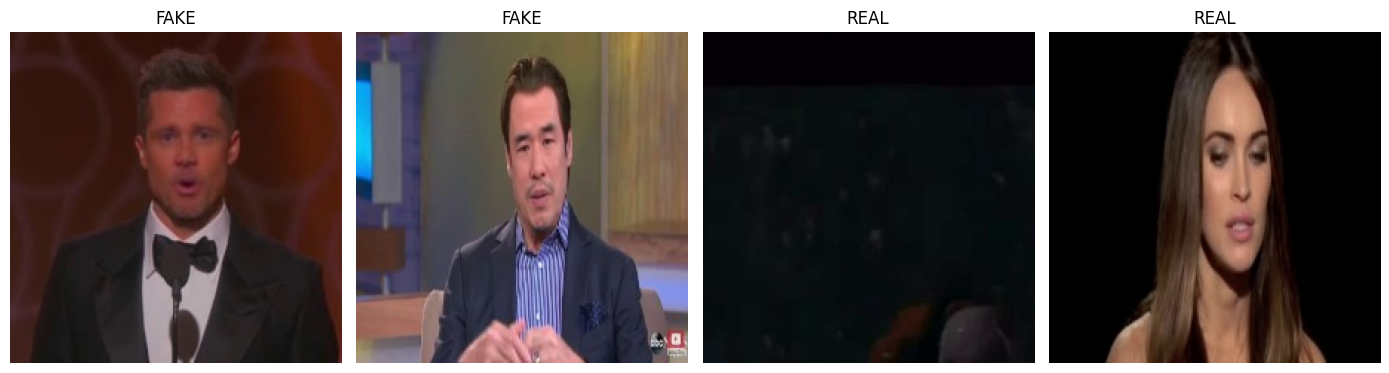

In [13]:
fig, axes = plt.subplots(1,4,figsize=(14, 4))
sample_paths = []

for class_name in ["FAKE", "REAL"]:
    folder = os.path.join(FRAME_ROOT,"train",class_name)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith(".jpg")
    ]

    if len(images) >= 2:
        sample_paths.extend([
            os.path.join(folder, images[0]),
            os.path.join(folder, images[1])
        ])


for i, image_path in enumerate(sample_paths):
    image = Image.open(image_path)
    axes[i].imshow(image)
    axes[i].set_title(os.path.basename(os.path.dirname(image_path)))
    axes[i].axis("off")

plt.tight_layout()
plt.show()

Part 3 — ResNet50 model preparation

In [14]:
import torch
import torch.nn as nn
import numpy as np
import copy

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

if device.type == "cuda":
    print("GPU:",torch.cuda.get_device_name(0))
else:
    print("Warning: Training will run on CPU.")

Using device: cuda
GPU: Tesla T4


In [31]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=5),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transformations created!")

Image transformations created!


In [16]:
train_ds = datasets.ImageFolder(
    os.path.join(FRAME_ROOT,"train"),
    transform=train_transform
)

val_ds = datasets.ImageFolder(
    os.path.join(FRAME_ROOT,"val"),
    transform=eval_transform
)

print("Class mapping:", train_ds.class_to_idx)
print("Training frames:", len(train_ds))
print("Validation frames:", len(val_ds))

assert train_ds.class_to_idx == val_ds.class_to_idx

Class mapping: {'FAKE': 0, 'REAL': 1}
Training frames: 25541
Validation frames: 4510


In [17]:
class_counts = np.bincount(train_ds.targets)

class_weights = len(train_ds) / (len(class_counts) * class_counts)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

print("Class counts [FAKE, REAL]:")
print(class_counts)

print("\nClass weights:")
print(class_weights)

Class counts [FAKE, REAL]:
[22520  3021]

Class weights:
tensor([0.5671, 4.2272], device='cuda:0')


In [32]:
train_loader = DataLoader(
    train_ds,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_ds,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 799
Validation batches: 141


In [38]:

# ResNet50 initialization
weights = models.ResNet50_Weights.DEFAULT

model = models.resnet50(weights=weights)

model.fc = nn.Linear(
    model.fc.in_features,
    2
)

# LOAD PREVIOUSLY TRAINED MODEL
previous_weights = torch.load(
    "/content/drive/MyDrive/celebdf_resnet50_best.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(previous_weights)

print("Previous Celeb-DF weights loaded successfully!")

# Freeze all layers
for param in model.parameters():
    param.requires_grad = False

# Unfreeze layer4
for param in model.layer4.parameters():
    param.requires_grad = True

# Unfreeze classification layer
for param in model.fc.parameters():
    param.requires_grad = True

model = model.to(device)

print("ResNet50 ready for fine-tuning!")

Previous Celeb-DF weights loaded successfully!
ResNet50 ready for fine-tuning!


In [39]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW([
        {"params": model.layer4.parameters(), "lr": 1e-5},
        {"params": model.fc.parameters(), "lr": 1e-4}
    ],weight_decay=1e-4)

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Optimizer initialized!")

Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 1e-05
    maximize: False
    weight_decay: 0.0001

Parameter Group 1
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)
Optimizer initialized!


In [40]:
start_epoch = 0
best_val_loss = float("inf")

print("Starting new fine-tuning experiment!")
print("Starting from epoch 1")

Starting new fine-tuning experiment!
Starting from epoch 1


Part 4 — Train ResNet50

In [41]:

EPOCHS = 10

best_val_loss = float("inf")
best_state = None

# Early stopping settings
patience = 4
early_stop_counter = 0

# Learning rate scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "learning_rate": []
}

for epoch in range(start_epoch, EPOCHS):
    # TRAINING
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader,
        desc=f"Training Epoch {epoch+1}"
    ):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)

        predictions = outputs.argmax(1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # VALIDATION
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)

            predictions = outputs.argmax(1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    # LEARNING RATE SCHEDULER
    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]


    # SAVE HISTORY
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["learning_rate"].append(current_lr)

    # DISPLAY RESULTS
    print(f"\nEpoch {epoch+1}/{EPOCHS}")

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")

    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.4f}")

    print(f"Learning Rate: {current_lr:.7f}")

    # SAVE BEST MODEL
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        early_stop_counter = 0

        torch.save(
            best_state,
            "/content/drive/MyDrive/celebdf_resnet50_best.pth"
        )
        print("Best model updated!")
    else:
        early_stop_counter += 1
        print("Validation loss did not improve.")

    # SAVE CHECKPOINT EVERY EPOCH
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_val_loss": best_val_loss,
        "early_stop_counter": early_stop_counter,
        "history": history

    }, checkpoint_path)

    print("Training checkpoint saved!")

    # EARLY STOPPING
    if early_stop_counter >= patience:
        print("\nEarly stopping triggered!")
        break

# RESTORE BEST MODEL
if best_state is None:
    raise RuntimeError("Training did not produce a model checkpoint.")

model.load_state_dict(best_state)
print("\nTraining completed!")
print("Best validation loss:", best_val_loss)


Training Epoch 1:   0%|          | 0/799 [00:00<?, ?it/s]


Epoch 1/10
Train Loss: 0.0281
Train Accuracy: 0.9902
Validation Loss: 0.2504
Validation Accuracy: 0.9421
Learning Rate: 0.0000100
Best model updated!
Training checkpoint saved!


Training Epoch 2:   0%|          | 0/799 [00:00<?, ?it/s]


Epoch 2/10
Train Loss: 0.0234
Train Accuracy: 0.9919
Validation Loss: 0.2877
Validation Accuracy: 0.9408
Learning Rate: 0.0000100
Validation loss did not improve.
Training checkpoint saved!


Training Epoch 3:   0%|          | 0/799 [00:00<?, ?it/s]


Epoch 3/10
Train Loss: 0.0204
Train Accuracy: 0.9923
Validation Loss: 0.3207
Validation Accuracy: 0.9421
Learning Rate: 0.0000100
Validation loss did not improve.
Training checkpoint saved!


Training Epoch 4:   0%|          | 0/799 [00:00<?, ?it/s]


Epoch 4/10
Train Loss: 0.0195
Train Accuracy: 0.9934
Validation Loss: 0.3321
Validation Accuracy: 0.9457
Learning Rate: 0.0000050
Validation loss did not improve.
Training checkpoint saved!


Training Epoch 5:   0%|          | 0/799 [00:00<?, ?it/s]


Epoch 5/10
Train Loss: 0.0163
Train Accuracy: 0.9943
Validation Loss: 0.3250
Validation Accuracy: 0.9441
Learning Rate: 0.0000050
Validation loss did not improve.
Training checkpoint saved!

Early stopping triggered!

Training completed!
Best validation loss: 0.2504350416162826


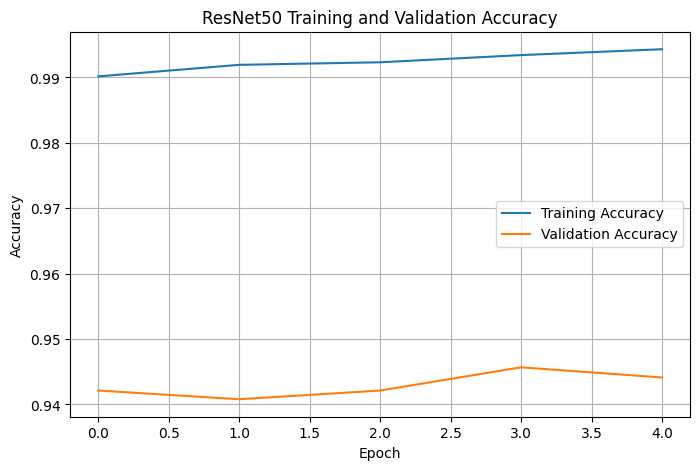

In [64]:
plt.figure(figsize=(8, 5))

plt.plot(history["train_acc"], label="Training Accuracy")

plt.plot(history["val_acc"], label="Validation Accuracy")

plt.title("ResNet50 Training and Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)
plt.show()

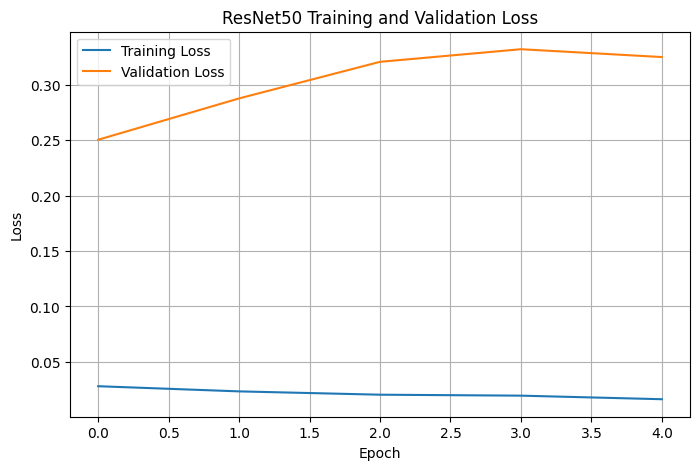

In [65]:
plt.figure(figsize=(8, 5))

plt.plot(history["train_loss"], label="Training Loss")

plt.plot(history["val_loss"],label="Validation Loss")

plt.title("ResNet50 Training and Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()

In [66]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "class_to_idx": train_ds.class_to_idx,
    "architecture": "resnet50",
    "epochs": EPOCHS,
    "best_val_loss": best_val_loss
}

torch.save(checkpoint, "/content/celebdf_resnet50.pth")

print("ResNet50 model saved successfully!")
print("Location: /content/celebdf_resnet50.pth")

ResNet50 model saved successfully!
Location: /content/celebdf_resnet50.pth


In [67]:
# SAVE FINAL FINE-TUNED RESNET50 MODEL
checkpoint = {
    "model_state_dict": model.state_dict(),
    "class_to_idx": train_ds.class_to_idx,
    "architecture": "resnet50",
    "epochs": EPOCHS,
    "best_val_loss": best_val_loss,
    "history": history,
    "input_size": 224,
    "mean": [0.485, 0.456, 0.406],
    "std": [0.229, 0.224, 0.225]
}

save_path = "/content/drive/MyDrive/celebdf_resnet50_finetuned.pth"

torch.save(checkpoint, save_path)

print("Fine-tuned ResNet50 saved successfully!")
print("Location:", save_path)
print("Best validation loss:", best_val_loss)
print("Classes:", train_ds.class_to_idx)

Fine-tuned ResNet50 saved successfully!
Location: /content/drive/MyDrive/celebdf_resnet50_finetuned.pth
Best validation loss: 0.2504350416162826
Classes: {'FAKE': 0, 'REAL': 1}


Part 5 — Model testing and evaluation

In [68]:
test_ds = datasets.ImageFolder(
    os.path.join(FRAME_ROOT,"test"),
    transform=eval_transform
)

test_loader = DataLoader(
    test_ds,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Test frames:", len(test_ds))
print("Class mapping:", test_ds.class_to_idx)

Test frames: 2590
Class mapping: {'FAKE': 0, 'REAL': 1}


In [69]:
model.eval()

all_preds = []
all_labels = []
all_probabilities = []

with torch.no_grad():

    for images, labels in tqdm(test_loader,desc="Testing ResNet50"):
        images = images.to(device)

        # Get model outputs
        outputs = model(images)

        # Convert outputs into probabilities
        probabilities = torch.softmax(outputs,dim=1)

        # Get predicted classes
        predictions = outputs.argmax(1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probabilities = np.array(all_probabilities)

print("Testing completed!")
print("Total predictions:", len(all_preds))

Testing ResNet50:   0%|          | 0/81 [00:00<?, ?it/s]

Testing completed!
Total predictions: 2590


In [70]:
fake_label = test_ds.class_to_idx["FAKE"]

accuracy = accuracy_score(
    all_labels,
    all_preds
)

precision = precision_score(
    all_labels,
    all_preds,
    pos_label=fake_label,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_preds,
    pos_label=fake_label,
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_preds,
    pos_label=fake_label,
    zero_division=0
)

print("RESNET50 TEST RESULTS")
print("----------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

RESNET50 TEST RESULTS
----------------------------
Accuracy:  0.8869
Precision: 0.8732
Recall:    0.9682
F1 Score:  0.9183


In [71]:
class_names = [
    name for name, idx in sorted(
        test_ds.class_to_idx.items(),
        key=lambda item: item[1]
    )]

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=class_names,
        zero_division=0
    ))

              precision    recall  f1-score   support

        FAKE       0.87      0.97      0.92      1700
        REAL       0.92      0.73      0.82       890

    accuracy                           0.89      2590
   macro avg       0.90      0.85      0.87      2590
weighted avg       0.89      0.89      0.88      2590



Confusion Matrix:
[[1646   54]
 [ 239  651]]


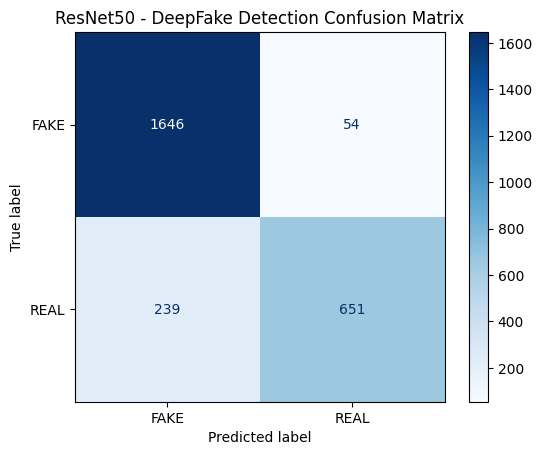

In [72]:
cm = confusion_matrix(all_labels,all_preds)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues",values_format="d")
plt.title("ResNet50 - DeepFake Detection Confusion Matrix")
plt.show()

In [73]:
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision","Recall","F1 Score"],
    "Score": [accuracy, precision, recall, f1]
})

display(results)
results.to_csv("/content/resnet50_results.csv",index=False)
print("Evaluation results saved!")

,Metric,Score
0,Accuracy,0.886873
1,Precision,0.873210
2,Recall,0.968235
3,F1 Score,0.918271


Evaluation results saved!


Part 6 — Test your own video

In [74]:
import torch
import torch.nn as nn

from torchvision import models, transforms
from PIL import Image

import cv2
import numpy as np
from google.colab import files

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Rebuild ResNet50 architecture
model = models.resnet50(weights=None)

# Replace final layer
num_features = model.fc.in_features
model.fc = nn.Linear(num_features,2)

# Load checkpoint
checkpoint = torch.load(
    "/content/celebdf_resnet50.pth",
    map_location=device,
    weights_only=False
)

# Load trained weights
model.load_state_dict(checkpoint["model_state_dict"])


# Load class mapping
class_to_idx = checkpoint["class_to_idx"]

idx_to_class = {
    idx: name
    for name, idx in class_to_idx.items()
}

# Move model to device
model = model.to(device)
model.eval()


print("ResNet50 loaded successfully!")
print("Class mapping:", class_to_idx)

ResNet50 loaded successfully!
Class mapping: {'FAKE': 0, 'REAL': 1}


In [75]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image preprocessing ready!")

Image preprocessing ready!


In [76]:
uploaded = files.upload()
video_path = next(iter(uploaded.keys()))

print("Uploaded video:", video_path)

Saving AI baby meme #trending #viral #funny #shorts.mp4 to AI baby meme #trending #viral #funny #shorts.mp4
Uploaded video: AI baby meme #trending #viral #funny #shorts.mp4


In [77]:
def predict_video(video_path, num_frames=20):

    cap = cv2.VideoCapture(video_path)

    # Get total number of frames
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        raise ValueError("Could not read this video.")

    # Select frames throughout the video
    frame_indices = np.linspace(
        0,
        total_frames - 1,
        min(num_frames, total_frames),
        dtype=int
    )

    fake_probs = []

    # Process each selected frame
    for frame_index in frame_indices:

        cap.set(cv2.CAP_PROP_POS_FRAMES,int(frame_index))

        success, frame = cap.read()

        if not success:
            continue

        # Convert BGR to RGB
        frame = cv2.cvtColor(frame,cv2.COLOR_BGR2RGB)


        # Convert frame to PIL image
        image = Image.fromarray(frame)

        # Apply preprocessing
        image_tensor = transform(image).unsqueeze(0).to(device)


        # Make prediction
        with torch.no_grad():
            outputs = model(image_tensor)
            probabilities = torch.softmax(outputs,dim=1)


        # Get FAKE class probability
        fake_index = class_to_idx["FAKE"]

        fake_probability = probabilities[0,fake_index].item()

        fake_probs.append(fake_probability)

    cap.release()


    if len(fake_probs) == 0:
        raise ValueError("No readable frames were found.")

    # Calculate average probabilities
    avg_fake = float(np.mean(fake_probs))
    avg_real = 1.0 - avg_fake


    # Display results
    print("VIDEO ANALYSIS RESULTS")
    print("----------------------------")
    print("Frames analyzed:",len(fake_probs))
    print(f"Average FAKE score: {avg_fake:.2%}")
    print(f"Average REAL score: {avg_real:.2%}")

    # Final prediction
    if avg_fake >= 0.5:
        print("\nPrediction: FAKE")
    else:
        print("\nPrediction: REAL")

    return avg_fake

In [78]:
fake_score = predict_video(
    video_path,
    num_frames=20
)

VIDEO ANALYSIS RESULTS
----------------------------
Frames analyzed: 20
Average FAKE score: 39.77%
Average REAL score: 60.23%

Prediction: REAL


Experiment 2: Balanced Training

In [80]:
from torch.utils.data import WeightedRandomSampler

# Count images in each class
class_counts = np.bincount(train_ds.targets)

# Calculate class weights for sampling
sample_weights = 1.0 / class_counts

# Assign a weight to each image
weights = [sample_weights[label] for label in train_ds.targets]

# Create balanced sampler
sampler = WeightedRandomSampler(
    weights=weights,
    num_samples=len(weights),
    replacement=True
)

print("Weighted sampler created!")
print("FAKE images:", class_counts[0])
print("REAL images:", class_counts[1])

Weighted sampler created!
FAKE images: 22520
REAL images: 3021


In [81]:
train_loader = DataLoader(
    train_ds,
    batch_size=32,
    sampler=sampler,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders updated!")

DataLoaders updated!


In [82]:
criterion = nn.CrossEntropyLoss()

# Use smaller learning rates for fine-tuning
optimizer = torch.optim.AdamW(
    [
        {
            "params": model.layer4.parameters(),
            "lr": 1e-5
        },
        {
            "params": model.fc.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

print("Loss function and optimizer ready!")

Loss function and optimizer ready!


In [83]:
EPOCHS = 10

best_val_loss = float("inf")

patience = 4
early_stop_counter = 0

best_state = None

# Separate file for the new experiment
best_model_path = "/content/drive/MyDrive/celebdf_resnet50_balanced_best.pth"

# Separate training checkpoint
checkpoint_path = "/content/drive/MyDrive/celebdf_resnet50_balanced_checkpoint.pth"

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

print("Balanced training experiment initialized!")

Balanced training experiment initialized!


In [84]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)
scheduler.step(val_loss)

In [85]:
for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    # Training
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss / train_total
    train_acc = train_correct / train_total

    # Validation
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss / val_total
    val_acc = val_correct / val_total

    # Update learning rate
    scheduler = None

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.4f}")

    print("Layer4 LR:", optimizer.param_groups[0]["lr"])
    print("FC LR:", optimizer.param_groups[1]["lr"])

    # Store results
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_state = copy.deepcopy(model.state_dict())

        torch.save({
            "model_state_dict": best_state,
            "class_to_idx": train_ds.class_to_idx,
            "architecture": "resnet50",
            "epoch": epoch + 1,
            "best_val_loss": best_val_loss,
            "threshold": 0.30
        }, best_model_path)

        early_stop_counter = 0

        print("Best balanced model saved!")

    else:

        early_stop_counter += 1

    # Save training checkpoint
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_loss": best_val_loss,
        "early_stop_counter": early_stop_counter,
        "history": history
    }, checkpoint_path)

    print("Checkpoint saved!")

    # Stop if validation loss does not improve
    if early_stop_counter >= patience:

        print("Early stopping triggered!")
        break

# Restore best model
if best_state is not None:

    model.load_state_dict(best_state)

print("\nBalanced training completed!")
print("Best validation loss:", best_val_loss)
print("Best model location:", best_model_path)


Epoch 1/10
Train Loss: 0.0456
Train Accuracy: 0.9841
Validation Loss: 0.2272
Validation Accuracy: 0.9401
Layer4 LR: 1e-05
FC LR: 0.0001
Best balanced model saved!
Checkpoint saved!

Epoch 2/10
Train Loss: 0.0243
Train Accuracy: 0.9916
Validation Loss: 0.2435
Validation Accuracy: 0.9461
Layer4 LR: 1e-05
FC LR: 0.0001
Checkpoint saved!

Epoch 3/10
Train Loss: 0.0199
Train Accuracy: 0.9938
Validation Loss: 0.2707
Validation Accuracy: 0.9499
Layer4 LR: 1e-05
FC LR: 0.0001
Checkpoint saved!

Epoch 4/10
Train Loss: 0.0185
Train Accuracy: 0.9940
Validation Loss: 0.3201
Validation Accuracy: 0.9488
Layer4 LR: 1e-05
FC LR: 0.0001
Checkpoint saved!

Epoch 5/10
Train Loss: 0.0165
Train Accuracy: 0.9950
Validation Loss: 0.3238
Validation Accuracy: 0.9475
Layer4 LR: 1e-05
FC LR: 0.0001
Checkpoint saved!
Early stopping triggered!

Balanced training completed!
Best validation loss: 0.22717538586077632
Best model location: /content/drive/MyDrive/celebdf_resnet50_balanced_best.pth


In [86]:
from sklearn.metrics import classification_report, confusion_matrix

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)

        predictions = (probabilities[:, 1] >= 0.30).long()

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_predictions,
    target_names=["FAKE", "REAL"]
))

print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

              precision    recall  f1-score   support

        FAKE       0.97      0.96      0.96      3975
        REAL       0.70      0.79      0.74       535

    accuracy                           0.94      4510
   macro avg       0.84      0.87      0.85      4510
weighted avg       0.94      0.94      0.94      4510

Confusion Matrix:
[[3799  176]
 [ 115  420]]


In [3]:
from google.colab import drive
drive.mount('/content/drive')
import os

folder = "/content/drive/MyDrive"

for root, dirs, files in os.walk(folder):
    for file in files:
        if file.endswith(".pth") or file.endswith(".pt"):
            print(os.path.join(root, file))

Mounted at /content/drive
/content/drive/MyDrive/celebdf_resnet50_best.pth
/content/drive/MyDrive/celebdf_resnet50_checkpoint.pth
/content/drive/MyDrive/celebdf_resnet50_finetuned.pth
/content/drive/MyDrive/celebdf_resnet50_balanced_best.pth
/content/drive/MyDrive/celebdf_resnet50_balanced_checkpoint.pth


In [5]:
from torchvision import models
import torch.nn as nn

# Recreate ResNet50 architecture
model = models.resnet50(weights=None)

# Set the final layer to 2 classes: FAKE and REAL
model.fc = nn.Linear(model.fc.in_features, 2)

# Move model to CPU
model = model.to(device)

print("ResNet50 architecture created successfully!")
model.load_state_dict(checkpoint["model_state_dict"])

model.eval()

print("Balanced model loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

ResNet50 architecture created successfully!
Balanced model loaded successfully!
Best epoch: 1
Best validation loss: 0.22717538586077632


In [6]:
import torch
import torchvision
import numpy as np

from torchvision import models, datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

device = torch.device("cpu")

print("Libraries imported successfully!")
print("Device:", device)
print("PyTorch version:", torch.__version__)
# Load the best balanced model checkpoint

checkpoint_path = "/content/drive/MyDrive/celebdf_resnet50_balanced_best.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Balanced model loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

Libraries imported successfully!
Device: cpu
PyTorch version: 2.14.1+cpu
Balanced model loaded successfully!
Best epoch: 1
Best validation loss: 0.22717538586077632


In [9]:
import os

drive_path = "/content/drive/MyDrive"

print("Google Drive folders:\n")

for item in os.listdir(drive_path):
    full_path = os.path.join(drive_path, item)

    if os.path.isdir(full_path):
        print("📁", item)
possible_path = "/content/drive/MyDrive/Deepfake_Project"

print("Deepfake_Project exists:", os.path.exists(possible_path))

if os.path.exists(possible_path):
    print(os.listdir(possible_path))

Google Drive folders:

📁 Colab Notebooks
📁 Deepfake_Project
Deepfake_Project exists: True
['celebdf_frames', 'manifests']


In [18]:
import pandas as pd
import os

manifest_path = "/content/drive/MyDrive/Deepfake_Project/manifests"

print("Manifest folder exists:", os.path.exists(manifest_path))

if os.path.exists(manifest_path):
    for root, dirs, files in os.walk(manifest_path):
        for file in files:
            print(os.path.join(root, file))

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for folder in dirs:
        if "celeb" in folder.lower() or "deepfake" in folder.lower():
            print(os.path.join(root, folder))

manifest_path = "/content/drive/MyDrive/Deepfake_Project/manifests"

for filename in ["train_videos.csv", "val_videos.csv", "test_videos.csv"]:

    file_path = os.path.join(manifest_path, filename)

    df = pd.read_csv(file_path)

    print("\n", filename)
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print(df.head())

import os

video_extensions = (".mp4", ".avi", ".mov", ".mkv")
found_videos = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.lower().endswith(video_extensions):
            found_videos.append(os.path.join(root, file))

print("Videos found:", len(found_videos))

for path in found_videos[:20]:
    print(path)


Manifest folder exists: True
/content/drive/MyDrive/Deepfake_Project/manifests/train_videos.csv
/content/drive/MyDrive/Deepfake_Project/manifests/val_videos.csv
/content/drive/MyDrive/Deepfake_Project/manifests/test_videos.csv
/content/drive/MyDrive/Deepfake_Project
/content/drive/MyDrive/Deepfake_Project/celebdf_frames

 train_videos.csv
Rows: 5109
Columns: ['path', 'video', 'label', 'class', 'relative_path', 'split']
                                                path               video  \
0  /kaggle/input/celeb-df-v2/Celeb-synthesis/id47...  id47_id43_0001.mp4   
1  /kaggle/input/celeb-df-v2/Celeb-synthesis/id39...  id39_id47_0002.mp4   
2  /kaggle/input/celeb-df-v2/Celeb-real/id38_0001...       id38_0001.mp4   
3  /kaggle/input/celeb-df-v2/Celeb-synthesis/id20...  id20_id34_0000.mp4   
4  /kaggle/input/celeb-df-v2/Celeb-synthesis/id26...  id26_id34_0006.mp4   

   label class                       relative_path  split  
0      1  FAKE  Celeb-synthesis/id47_id43_0001.mp4  train  


In [22]:
!pip -q install kagglehub

import kagglehub

path = kagglehub.dataset_download("reubensuju/celeb-df-v2")

print("Dataset restored at:", path)

Using Colab cache for faster access to the 'celeb-df-v2' dataset.
Dataset restored at: /kaggle/input/celeb-df-v2


In [23]:
import os
import cv2
import numpy as np
import pandas as pd
from tqdm import tqdm

# Dataset location
dataset_path = "/kaggle/input/celeb-df-v2"

# Validation manifest
manifest_path = "/content/drive/MyDrive/Deepfake_Project/manifests/val_videos.csv"

# Output folder
output_path = "/content/celebdf_frames/val"

FRAMES_PER_VIDEO = 5

# Read validation videos
df = pd.read_csv(manifest_path)

# Create FAKE and REAL folders
for category in ["FAKE", "REAL"]:
    os.makedirs(
        os.path.join(output_path, category),
        exist_ok=True
    )

successful = 0
failed = 0

for _, row in tqdm(df.iterrows(), total=len(df)):

    video_path = os.path.join(
        dataset_path,
        row["relative_path"]
    )

    category = row["class"]

    video_name = os.path.splitext(row["video"])[0]

    cap = cv2.VideoCapture(video_path)

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if not cap.isOpened() or total_frames == 0:
        failed += 1
        cap.release()
        continue

    frame_indices = np.linspace(
        0,
        total_frames - 1,
        min(FRAMES_PER_VIDEO, total_frames),
        dtype=int
    )

    saved_count = 0

    for i, frame_index in enumerate(frame_indices):

        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_index))

        ret, frame = cap.read()

        if not ret:
            continue

        # Convert BGR to RGB
        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        # Resize image
        frame = cv2.resize(frame, (224, 224))

        # Convert back to BGR for saving
        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_RGB2BGR
        )

        filename = f"{video_name}_{i}.jpg"

        save_path = os.path.join(
            output_path,
            category,
            filename
        )

        cv2.imwrite(
            save_path,
            frame,
            [cv2.IMWRITE_JPEG_QUALITY, 90]
        )

        saved_count += 1

    cap.release()

    if saved_count > 0:
        successful += 1
    else:
        failed += 1

print("\nVALIDATION FRAME EXTRACTION COMPLETE")
print("Videos processed:", successful)
print("Videos failed:", failed)

print("FAKE frames:", len(os.listdir(output_path + "/FAKE")))
print("REAL frames:", len(os.listdir(output_path + "/REAL")))
print("Total frames:",
      len(os.listdir(output_path + "/FAKE")) +
      len(os.listdir(output_path + "/REAL")))

100%|██████████| 902/902 [01:44<00:00,  8.59it/s]


VALIDATION FRAME EXTRACTION COMPLETE
Videos processed: 902
Videos failed: 0
FAKE frames: 3975
REAL frames: 535
Total frames: 4510


In [27]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

val_path = "/content/celebdf_frames/val"

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_ds = datasets.ImageFolder(
    root=val_path,
    transform=val_transform
)

val_loader = DataLoader(
    val_ds,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Classes:", val_ds.class_to_idx)
print("Total images:", len(val_ds))


Classes: {'FAKE': 0, 'REAL': 1}
Total images: 4510


In [30]:
import numpy as np
import torch
from tqdm.auto import tqdm
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Optimize CPU processing
torch.set_num_threads(4)

model.eval()
model.to("cpu")

val_probabilities = []
val_labels = []

print("Starting validation evaluation...")

with torch.inference_mode():

    for images, labels in tqdm(val_loader, desc="Evaluating"):

        images = images.to("cpu")

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)

        val_probabilities.extend(probabilities[:, 1].numpy())
        val_labels.extend(labels.numpy())

val_probabilities = np.array(val_probabilities)
val_labels = np.array(val_labels)

threshold = 0.30

val_predictions = (val_probabilities >= threshold).astype(int)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    val_labels,
    val_predictions,
    target_names=["FAKE", "REAL"]
))

print("CONFUSION MATRIX")
print(confusion_matrix(val_labels, val_predictions))

print("VALIDATION ACCURACY:", accuracy_score(val_labels, val_predictions))

Starting validation evaluation...


Evaluating:   0%|          | 0/141 [00:00<?, ?it/s]


CLASSIFICATION REPORT
              precision    recall  f1-score   support

        FAKE       0.97      0.96      0.96      3975
        REAL       0.70      0.79      0.74       535

    accuracy                           0.94      4510
   macro avg       0.84      0.87      0.85      4510
weighted avg       0.94      0.94      0.94      4510

CONFUSION MATRIX
[[3799  176]
 [ 115  420]]
VALIDATION ACCURACY: 0.9354767184035476


In [31]:
import os
import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

dataset_path = "/kaggle/input/celeb-df-v2"

manifest_path = "/content/drive/MyDrive/Deepfake_Project/manifests/test_videos.csv"

output_path = "/content/celebdf_frames/test"

FRAMES_PER_VIDEO = 5

df = pd.read_csv(manifest_path)

for category in ["FAKE", "REAL"]:
    os.makedirs(os.path.join(output_path, category), exist_ok=True)

successful = 0
failed = 0

for _, row in tqdm(df.iterrows(), total=len(df)):

    video_path = os.path.join(dataset_path, row["relative_path"])
    category = row["class"]
    video_name = os.path.splitext(row["video"])[0]

    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if not cap.isOpened() or total_frames == 0:
        failed += 1
        cap.release()
        continue

    frame_indices = np.linspace(
        0, total_frames - 1,
        min(FRAMES_PER_VIDEO, total_frames),
        dtype=int
    )

    saved_count = 0

    for i, frame_index in enumerate(frame_indices):

        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_index))
        ret, frame = cap.read()

        if not ret:
            continue

        frame = cv2.resize(frame, (224, 224))

        filename = f"{video_name}_{i}.jpg"

        save_path = os.path.join(
            output_path, category, filename
        )

        cv2.imwrite(
            save_path,
            frame,
            [cv2.IMWRITE_JPEG_QUALITY, 90]
        )

        saved_count += 1

    cap.release()

    if saved_count > 0:
        successful += 1
    else:
        failed += 1

print("\nTEST FRAME EXTRACTION COMPLETE")
print("Videos processed:", successful)
print("Videos failed:", failed)
print("FAKE frames:", len(os.listdir(output_path + "/FAKE")))
print("REAL frames:", len(os.listdir(output_path + "/REAL")))
print("Total frames:",
      len(os.listdir(output_path + "/FAKE")) +
      len(os.listdir(output_path + "/REAL")))

  0%|          | 0/518 [00:00<?, ?it/s]


TEST FRAME EXTRACTION COMPLETE
Videos processed: 518
Videos failed: 0
FAKE frames: 1700
REAL frames: 890
Total frames: 2590


In [32]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np
import torch

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_ds = datasets.ImageFolder(
    "/content/celebdf_frames/test",
    transform=test_transform
)

test_loader = DataLoader(
    test_ds,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Test classes:", test_ds.class_to_idx)
print("Total test images:", len(test_ds))

Test classes: {'FAKE': 0, 'REAL': 1}
Total test images: 2590


In [33]:
model.eval()

test_probabilities = []
test_labels = []

with torch.inference_mode():

    for images, labels in tqdm(test_loader, desc="Testing"):

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)

        test_probabilities.extend(
            probabilities[:, 1].numpy()
        )

        test_labels.extend(labels.numpy())

test_probabilities = np.array(test_probabilities)
test_labels = np.array(test_labels)

# Keep the threshold selected using validation data
threshold = 0.30

test_predictions = (test_probabilities >= threshold).astype(int)

print("\nFINAL TEST CLASSIFICATION REPORT")

print(classification_report(
    test_labels,
    test_predictions,
    target_names=["FAKE", "REAL"]
))

print("CONFUSION MATRIX")
print(confusion_matrix(test_labels, test_predictions))

print("FINAL TEST ACCURACY:",
      accuracy_score(test_labels, test_predictions))

Testing:   0%|          | 0/81 [00:00<?, ?it/s]


FINAL TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

        FAKE       0.89      0.93      0.91      1700
        REAL       0.86      0.77      0.81       890

    accuracy                           0.88      2590
   macro avg       0.87      0.85      0.86      2590
weighted avg       0.88      0.88      0.88      2590

CONFUSION MATRIX
[[1587  113]
 [ 204  686]]
FINAL TEST ACCURACY: 0.8776061776061777


In [34]:
import os
import torch

save_folder = "/content/drive/MyDrive/Deepfake_Project/models"

os.makedirs(save_folder, exist_ok=True)

final_checkpoint = {
    "architecture": "resnet50",
    "model_state_dict": model.cpu().state_dict(),
    "class_to_idx": {
        "FAKE": 0,
        "REAL": 1
    },
    "threshold": 0.30,
    "test_accuracy": 0.8776061776061777,
    "test_real_recall": 0.77,
    "test_fake_recall": 0.93,
    "input_size": 224
}

save_path = os.path.join(
    save_folder,
    "celebdf_resnet50_final.pth"
)

torch.save(final_checkpoint, save_path)

print("FINAL MODEL SAVED SUCCESSFULLY!")
print(save_path)
print("File size:", round(os.path.getsize(save_path) / (1024 * 1024), 2), "MB")

FINAL MODEL SAVED SUCCESSFULLY!
/content/drive/MyDrive/Deepfake_Project/models/celebdf_resnet50_final.pth
File size: 90.0 MB


FINAL TESTING

In [35]:

from google.colab import drive
drive.mount('/content/drive')

import os
import torch
import torch.nn as nn
from torchvision import models, transforms

# Find the saved model
final_path = "/content/drive/MyDrive/Deepfake_Project/models/celebdf_resnet50_final.pth"
backup_path = "/content/drive/MyDrive/celebdf_resnet50_balanced_best.pth"

if os.path.exists(final_path):
    checkpoint_path = final_path
elif os.path.exists(backup_path):
    checkpoint_path = backup_path
else:
    raise FileNotFoundError("Model checkpoint not found in Google Drive.")

print("Loading:", checkpoint_path)

# Load model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 2)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

# Same preprocessing used during evaluation
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Model loaded successfully!")
print("Device:", device)
print("Threshold: 0.30")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading: /content/drive/MyDrive/Deepfake_Project/models/celebdf_resnet50_final.pth
Model loaded successfully!
Device: cpu
Threshold: 0.30


In [37]:

import cv2
import numpy as np
import torch
from google.colab import files
from PIL import Image

# Upload your video
uploaded = files.upload()

video_path = next(iter(uploaded.keys()))

# Open video
cap = cv2.VideoCapture(video_path)

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if total_frames <= 0:
    cap.release()
    raise ValueError("Could not read this video.")

# Select 20 evenly spaced frames
number_of_frames = min(20, total_frames)
frame_indices = np.linspace(
    0, total_frames - 1,
    number_of_frames,
    dtype=int
)

probabilities = []

for frame_number in frame_indices:

    cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_number))
    success, frame = cap.read()

    if not success:
        continue

    # Convert BGR to RGB
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    # Preprocess
    image_tensor = transform(frame).unsqueeze(0).to(device)

    # Predict
    with torch.no_grad():
        outputs = model(image_tensor)
        probs = torch.softmax(outputs, dim=1)

        # Class index 1 = REAL
        real_probability = probs[0, 1].item()

    probabilities.append(real_probability)

cap.release()

if len(probabilities) == 0:
    raise ValueError("No frames could be extracted from the video.")

# Calculate average REAL probability
average_real = np.mean(probabilities)

# Threshold selected using validation data
THRESHOLD = 0.30

if average_real >= THRESHOLD:
    prediction = "REAL"
else:
    prediction = "FAKE"

print("\n========== VIDEO TEST RESULTS ==========")
print("Video:", video_path)
print("Frames analyzed:", len(probabilities))
print("Average REAL probability:", round(average_real * 100, 2), "%")
print("Average FAKE probability:", round((1 - average_real) * 100, 2), "%")
print("----------------------------------------")
print("FINAL VIDEO PREDICTION:", prediction)
print("========================================")

# Show individual frame predictions
for i, probability in enumerate(probabilities):
    frame_prediction = "REAL" if probability >= THRESHOLD else "FAKE"
    print(
        f"Frame {i + 1}: "
        f"{frame_prediction} | "
        f"REAL probability: {probability * 100:.2f}%"
    )


Saving Haaland Watermelon Magic Trick! 🍉🌭 #football #parody #haaland.mp4 to Haaland Watermelon Magic Trick! 🍉🌭 #football #parody #haaland.mp4

========== VIDEO TEST RESULTS ==========
Video: Haaland Watermelon Magic Trick! 🍉🌭 #football #parody #haaland.mp4
Frames analyzed: 20
Average REAL probability: 13.17 %
Average FAKE probability: 86.83 %
----------------------------------------
FINAL VIDEO PREDICTION: FAKE
Frame 1: FAKE | REAL probability: 28.45%
Frame 2: FAKE | REAL probability: 21.94%
Frame 3: FAKE | REAL probability: 23.05%
Frame 4: FAKE | REAL probability: 1.34%
Frame 5: FAKE | REAL probability: 17.63%
Frame 6: FAKE | REAL probability: 8.75%
Frame 7: FAKE | REAL probability: 1.33%
Frame 8: FAKE | REAL probability: 2.14%
Frame 9: FAKE | REAL probability: 0.15%
Frame 10: FAKE | REAL probability: 0.02%
Frame 11: FAKE | REAL probability: 3.26%
Frame 12: FAKE | REAL probability: 1.00%
Frame 13: FAKE | REAL probability: 0.24%
Frame 14: FAKE | REAL probability: 27.58%
Frame 15: REAL 